# A3 - Correlation and linear regression
Probability and Statistics<br>
Name(s): Vilho Pesonen<br>
Date: 19.11.2026<br>
No AI used<br>
[Helsinki Metropolia University of Applied Sciences](https://www.metropolia.fi/en)
  

## Introduction

The following problems uses data and idea from **[OpenIntro Statistics](https://www.openintro.org/book/os/)**. The original Notebook **[Introduction to linear regression](https://github.com/akmand/stats_tutorials/blob/main/ch8_simple_regression.ipynb)** explains the background. More detailed explanation of the variables and their analysis can be read from **[Baseball statistics](https://en.wikipedia.org/wiki/Baseball_statistics)** and **[Sabermetrics](https://en.wikipedia.org/wiki/Sabermetrics)**-

This assignment follows the original material's **[Creative Commons Attribution-ShareAlike 3.0 Unported](https://creativecommons.org/licenses/by-sa/3.0/)** license policy. The data file can be found from OMA.

In [1]:
    # Import libraries
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Read data
data = pd.read_csv("mlbbat10.csv")

## Problem 1.

Coding:
- Calculate the descriptive statistics for the whole dataset.
- Plot the histograms of the variables `run` and `at_bat`.
- Plot the scatterplot between `run`and `at_bat`. Use `at_bat` as [independent](https://en.wikipedia.org/wiki/Regression_analysis) and `run` as [dependent variable](https://en.wikipedia.org/wiki/Dependent_and_independent_variables).

Questions:

a) Describe in your own words the statistics for **<a href="https://en.wikipedia.org/wiki/Run_(baseball)">run</a>** and **[at_bat](https://en.wikipedia.org/wiki/At_bat)** variables.<br>
b) Describe *by words* (interpret the scatterplot) how does the relationship between `at_bat` and `run` look like.<br>
c) If you knew in advance a player's time `at_bat`, would you be comfortable to predict the `run` score? Explain why.

              game       at_bat          run          hit       double  \
count  1199.000000  1199.000000  1199.000000  1199.000000  1199.000000   
mean     50.534612   137.909091    17.771476    35.491243     7.077565   
std      49.544371   188.126913    27.051262    51.908498    10.812941   
min       1.000000     0.000000     0.000000     0.000000     0.000000   
25%       8.000000     1.000000     0.000000     0.000000     0.000000   
50%      31.000000    37.000000     3.000000     6.000000     1.000000   
75%      84.000000   225.000000    26.500000    56.000000    11.000000   
max     162.000000   680.000000   115.000000   214.000000    49.000000   

            triple     home_run          rbi   total_base         walk  \
count  1199.000000  1199.000000  1199.000000  1199.000000  1199.000000   
mean      0.722269     3.847373    16.920767    55.555463    13.159299   
std       1.601990     7.372345    26.636637    83.717936    20.737459   
min       0.000000     0.000000     0

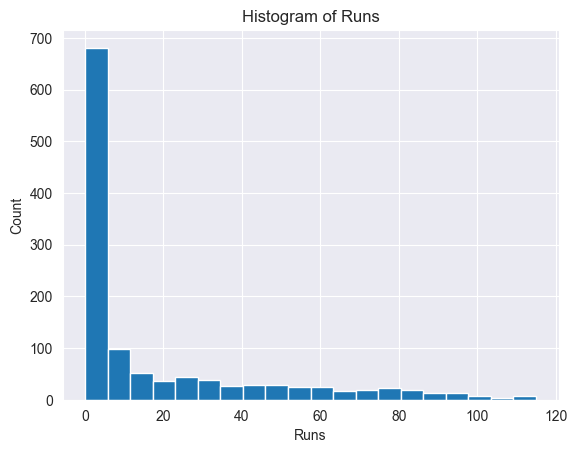

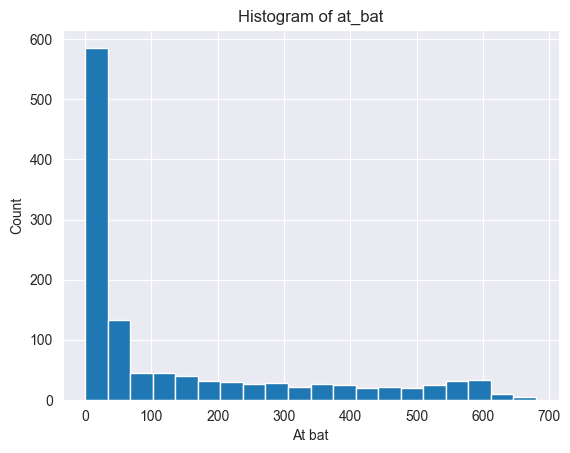

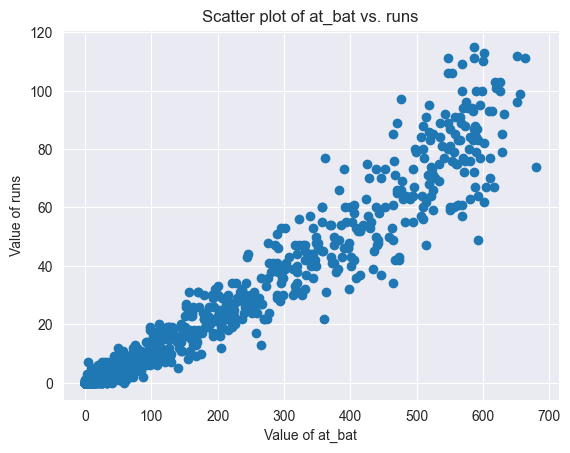

In [10]:
# Your code
descriptive = data.describe()
print(descriptive)
x1=data["run"]
x2=data["at_bat"]

plt.hist(x1, bins=20)
plt.xlabel("Runs")
plt.ylabel("Count")
plt.title('Histogram of Runs')
plt.show()

plt.hist(x2, bins=20)
plt.xlabel('At bat')
plt.ylabel('Count')
plt.title('Histogram of at_bat')
plt.show()

plt.scatter(x2,x1)
plt.title('Scatter plot of at_bat vs. runs')
plt.xlabel('Value of at_bat')
plt.ylabel('Value of runs')
plt.grid()
plt.show()


**Answers:** <br>
a) Run counts how many times a player got a run. At_bat counts how many times a player was at a bat. There are many players who did not have any runs or at_bats. Very small percent had lots of runs or lots of at bats<br>
b) It shows linear relationships. As at_bat increases also runs increase. But there are many points near zero or at zero.<br>
c) Yes because there is a strong correlation with runs

## Problem 2.

Coding:
- Calculate the correlation coefficient between the `run` and `at_bat`.
- Using any method, like `numpy.polyfit()` or `scipy.stats.linregress()`, find the best regression line that fits to the data.
- Plot the scatterplot between variables `at_bat` and `run`.
- Add the best fitting regression line to the graph.
- Add the results of the correlation calculation either into the title of the graph or legend box.
- Decorate the graph with suitable labels, grid-lines.
- Use different colors for the scatter-plot and the regression line.

Questions:

a) How the `at_bat` and `run` are correlated? Interpret the results of correlation calculations.<br>
b) If the player is `at_bat` 400 times in a year, what is his `run` score?<br>
c) How certain you would be about that score? Explain why.<br>

             run    at_bat
run     1.000000  0.970168
at_bat  0.970168  1.000000


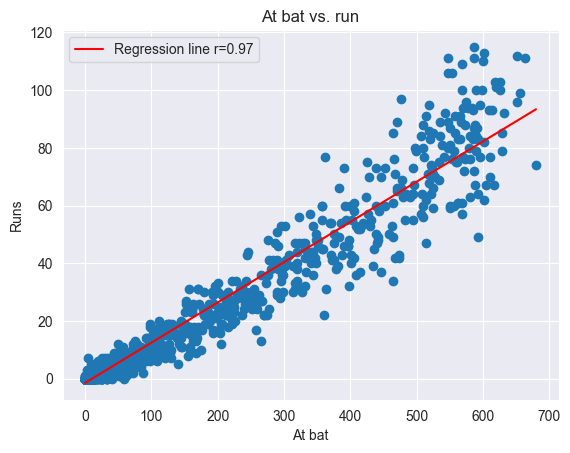

Runs if 400 times at bat 54.33


In [23]:
# Your code
from scipy.stats import linregress

var = ['run', 'at_bat']
x = data['at_bat']
y = data['run']
cor=data[var].corr()
print(cor)

r = linregress(x, y)
slope=r.slope
intercept=r.intercept
best=slope*x+intercept
corr=r.rvalue
plt.scatter(x,y)
plt.plot(x,best,color='red',label=f'Regression line r={corr:.2f}')
plt.title('At bat vs. run')
plt.xlabel('At bat')
plt.xlabel("At bat")
plt.ylabel('Runs')
plt.legend()
plt.show()
runs=slope*400+intercept
print(f'Runs if 400 times at bat {runs:.2f}')


**Answers:**<br>
a) correlation is 0.97. This means linear correlation<br>
b) 54 runs<br>
c) Very confident by looking at the scatter plot and the regression line we can see that it is near the 54, but we cant be 100% sure<br>

## Problem 3.

Study the other variables in the dataset. Find the variable that could best predict the `run` score. Explain which one of the variables you would select and why.

In [32]:
# Your code
predict=data.corr(numeric_only=True)['run']
print(predict)

game               0.903774
at_bat             0.970168
run                1.000000
hit                0.977381
double             0.949386
triple             0.684214
home_run           0.859812
rbi                0.945531
total_base         0.981973
walk               0.925169
strike_out         0.907874
stolen_base        0.642059
caught_stealing    0.684150
obp                0.486126
slg                0.507882
bat_avg            0.476034
Name: run, dtype: float64


**Answer:**<br>
based on the data we can see that hit has the highest correlation with run, that is why I would select hit
